In [ ]:
"""
Phase 2: NLP EDA on the 3700-record reference dataset.
This dataset is NOT used for training. It has gold sentiment_score + sentiment_label
already computed, and is only used later (Phase 4) to validate a pretrained model.
Here we just check that the reference labels themselves are clean and usable.
"""

In [1]:
%matplotlib inline
import ast #For literal evaluation
import re
from collections import Counter
 
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
# ---------------- CONFIG (edit to match your file) ----------------
REF_PATH = "reviews/3700_review.csv"
REVIEW_COL = "review"
SCORE_DICT_COL = "sentiment score"   # stringified dict: {'neg':.., 'neu':.., 'pos':.., 'compound':..}
TOKENS_COL = "review for sentiment analysis"                # stringified list of words; set to None if not present
LABEL_COL = "relative sentiments"        # categorical: positive / negative / neutral
# --------------------------------------------------------------------

In [3]:
df = pd.read_csv(REF_PATH)
print(f"Rows: {len(df)}")
print(df[[REVIEW_COL, SCORE_DICT_COL, LABEL_COL]].isna().sum())

Rows: 3700
review                 7
sentiment score        0
relative sentiments    0
dtype: int64


In [5]:
df['relative sentiments'].head(5)

0    negative
1    negative
2    negative
3    negative
4    negative
Name: relative sentiments, dtype: object

In [7]:
df['relative sentiments'].tail(5)

3695     neutral
3696    negative
3697    negative
3698    negative
3699    negative
Name: relative sentiments, dtype: object

In [4]:
df.head(5)

,Unnamed: 0,index,Rating,car_year,brand_name,date,review,review for sentiment analysis,sentiment score,relative sentiments
0,0,13,1.0,2015,Audi,2015-12-23,dissapointment interested want read review s8 ...,"['dissapointment', 'interested', 'want', 'read...","{'neg': 0.142, 'neu': 0.726, 'pos': 0.132, 'co...",negative
1,1,22,4.0,2014,Audi,2017-10-07,spectacular failure see review add name list p...,"['spectacular', 'failure', 'see', 'review', 'a...","{'neg': 0.338, 'neu': 0.528, 'pos': 0.133, 'co...",negative
2,2,26,1.0,2012,Audi,2018-07-17,beguiled buyer purchased leave return loved wa...,"['beguiled', 'buyer', 'purchased', 'leave', 'r...","{'neg': 0.191, 'neu': 0.693, 'pos': 0.117, 'co...",negative
3,3,36,1.0,2012,Audi,2016-04-28,q5 's year engine died dealership wanted charg...,"['q5', ""'s"", 'year', 'engine', 'died', 'dealer...","{'neg': 0.259, 'neu': 0.657, 'pos': 0.084, 'co...",negative
4,4,37,3.0,2012,Audi,2016-01-27,sporty quality premium radar wanted sporty col...,"['sporty', 'quality', 'premium', 'radar', 'wan...","{'neg': 0.102, 'neu': 0.802, 'pos': 0.095, 'co...",negative


In [5]:
df.tail(5)

,Unnamed: 0,index,Rating,car_year,brand_name,date,review,review for sentiment analysis,sentiment score,relative sentiments
3695,3695,31924,4.00,2015,Mercedes-Benz,2015-12-20,make sure know package want features/upgrades ...,"['make', 'sure', 'know', 'package', 'want', 'f...","{'neg': 0.112, 'neu': 0.776, 'pos': 0.112, 'co...",neutral
3696,3696,31926,3.00,2015,Mercedes-Benz,2015-10-18,thrilled basic nothing exciting eco feature da...,"['thrilled', 'basic', 'nothing', 'exciting', '...","{'neg': 0.237, 'neu': 0.648, 'pos': 0.114, 'co...",negative
3697,3697,31929,2.00,2015,Mercedes-Benz,2015-10-03,front cv joint problem gla matic september14th...,"['front', 'cv', 'joint', 'problem', 'gla', 'ma...","{'neg': 0.216, 'neu': 0.655, 'pos': 0.129, 'co...",negative
3698,3698,31934,4.00,2015,Mercedes-Benz,2015-05-19,delightful driving gla250 half problem parked ...,"['delightful', 'driving', 'gla250', 'half', 'p...","{'neg': 0.192, 'neu': 0.628, 'pos': 0.18, 'com...",negative
3699,3699,31936,2.75,2015,Mercedes-Benz,2015-01-20,steering wheel module first month driving erro...,"['steering', 'wheel', 'module', 'first', 'mont...","{'neg': 0.171, 'neu': 0.829, 'pos': 0.0, 'comp...",negative


In [8]:
def safe_literal_eval(x):
    """Converts a stringified dict/list back to a real Python object. Returns None on failure."""
    try:
        return ast.literal_eval(x)
    except (ValueError, SyntaxError, TypeError):
        return None
 
 
# Parse the dict column into 4 separate numeric columns
parsed_scores = df[SCORE_DICT_COL].apply(safe_literal_eval)
n_failed = parsed_scores.isna().sum()
if n_failed:
    print(f"WARNING: {n_failed} rows failed to parse {SCORE_DICT_COL} - check format")
 
df["score_neg"] = parsed_scores.apply(lambda d: d.get("neg") if isinstance(d, dict) else None)
df["score_neu"] = parsed_scores.apply(lambda d: d.get("neu") if isinstance(d, dict) else None)
df["score_pos"] = parsed_scores.apply(lambda d: d.get("pos") if isinstance(d, dict) else None)
df["score_compound"] = parsed_scores.apply(lambda d: d.get("compound") if isinstance(d, dict) else None)

In [9]:
# Parse tokens column if present
if TOKENS_COL and TOKENS_COL in df.columns:
    df["tokens_parsed"] = df[TOKENS_COL].apply(safe_literal_eval)
else:
    df["tokens_parsed"] = None

## Graphs

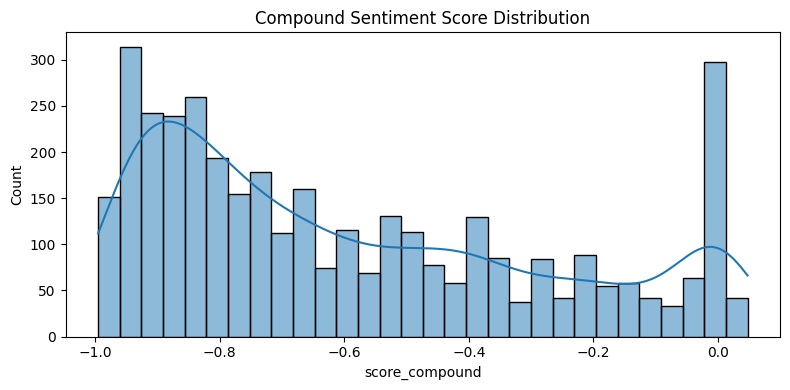

In [10]:
# 1. Sentiment score distribution (using compound - single overall score, -1 to 1)
plt.figure(figsize=(8, 4))
sns.histplot(df["score_compound"], bins=30, kde=True)
plt.title("Compound Sentiment Score Distribution")
plt.tight_layout()
plt.show()

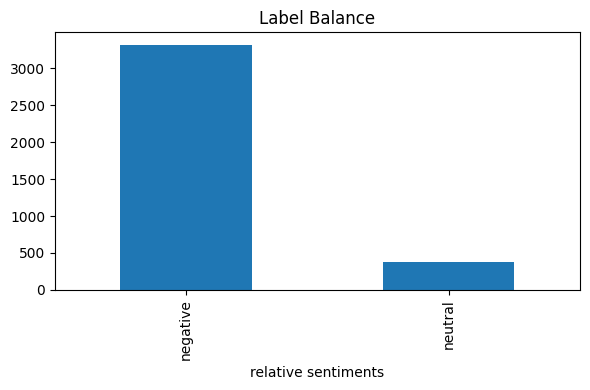


Label balance (%):
relative sentiments
negative    89.8
neutral     10.2
Name: proportion, dtype: float64


In [11]:
# 2. Label balance
plt.figure(figsize=(6, 4))
df[LABEL_COL].value_counts().plot(kind="bar")
plt.title("Label Balance")
plt.tight_layout()
plt.show()
print("\nLabel balance (%):")
print((df[LABEL_COL].value_counts(normalize=True) * 100).round(1))

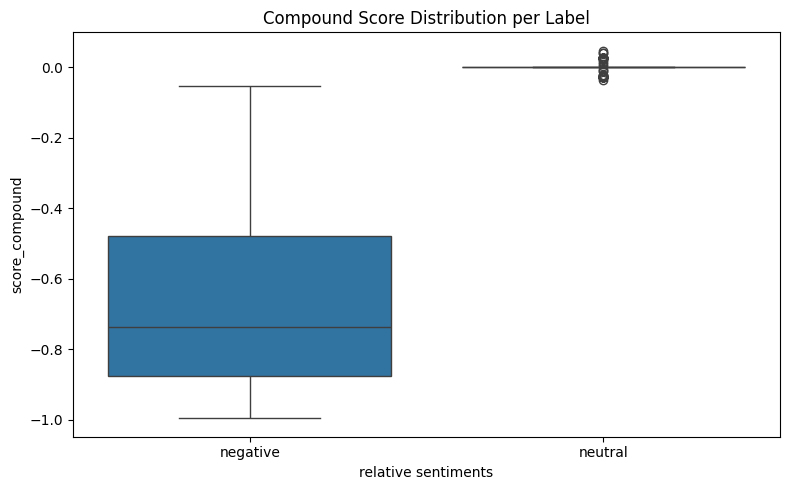

In [12]:
# 3. Score vs label consistency
plt.figure(figsize=(8, 5))
sns.boxplot(x=LABEL_COL, y="score_compound", data=df)
plt.title("Compound Score Distribution per Label")
plt.tight_layout()
plt.show()

In [13]:
def flag_mismatch(row):
    """Flags rows where the label and compound score disagree."""
    label = str(row[LABEL_COL]).lower()
    score = row["score_compound"]
    if score is None:
        return False
    if "negative" in label and score > 0:
        return True
    return False


df["mismatch"] = df.apply(flag_mismatch, axis=1)
n_mismatch = df["mismatch"].sum()
print(f"\nMismatched rows (label disagrees with compound score sign): {n_mismatch} "
      f"({n_mismatch / len(df) * 100:.1f}%)")


Mismatched rows (label disagrees with compound score sign): 0 (0.0%)


In [14]:
# 4. Word frequency per sentiment class
STOPWORDS = set(ENGLISH_STOP_WORDS)
 
 
def words_from_row(row):
    """Uses the pre-computed tokens column if available and valid, else falls back
    to tokenizing the review text directly."""
    parsed = row["tokens_parsed"]
    if isinstance(parsed, list):
        return [str(w).lower() for w in parsed if str(w).lower() not in STOPWORDS and len(str(w)) >= 3]
    text = row[REVIEW_COL]
    return [w for w in re.findall(r"\b[a-z]{3,}\b", str(text).lower()) if w not in STOPWORDS]
 
 
df["clean_words"] = df.apply(words_from_row, axis=1)


Top words per sentiment class:

negative:
  problem: 2359
  time: 1497
  dealer: 1287
  engine: 1144
  issue: 933
  month: 883
  replaced: 883
  repair: 873
  service: 835
  buy: 829
  seat: 732
  bad: 729
  light: 726
  year: 717
  tire: 711
  transmission: 703
  driving: 681
  warranty: 676
  oil: 642
  've: 595


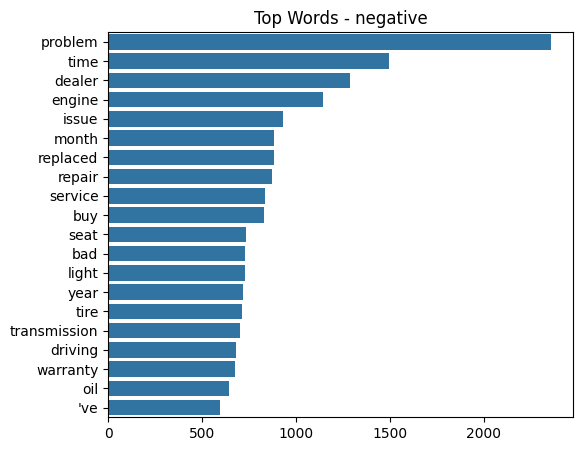


neutral:
  time: 87
  dealer: 59
  repair: 53
  issue: 51
  year: 49
  buy: 49
  replaced: 44
  problem: 43
  engine: 42
  seat: 38
  lot: 36
  brake: 36
  month: 34
  tire: 34
  shop: 34
  need: 32
  transmission: 31
  expensive: 30
  dealership: 30
  owned: 29


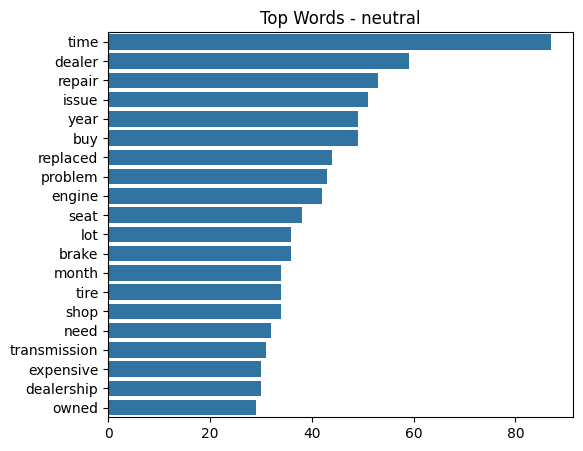

In [15]:
print("\nTop words per sentiment class:")

for label in df[LABEL_COL].dropna().unique():
    subset_words = df.loc[df[LABEL_COL] == label, "clean_words"]
    words = [w for word_list in subset_words for w in word_list]
    top = Counter(words).most_common(20)
    print(f"\n{label}:")
    for word, count in top:
        print(f"  {word}: {count}")
 
    plt.figure(figsize=(6, 5))
    labels_, counts_ = zip(*top) if top else ([], [])
    sns.barplot(x=list(counts_), y=list(labels_))
    plt.title(f"Top Words - {label}")
    plt.show()

In [16]:
import os

os.makedirs('data', exist_ok=True)

# Export Reference Validation[cite: 1]
export_df = df[[REVIEW_COL, 'score_compound', LABEL_COL]].copy()
export_df.rename(columns={
    REVIEW_COL: 'review', 
    LABEL_COL: 'sentiment_label'
}, inplace=True)

export_df.to_csv('data/reference_validation.csv', index=False)